# LAPORAN PROYEK COMPUTER VISION: DETEKSI MOBIL DAN ANALISIS TEKS (UAS)

Notebook ini menyajikan implementasi pemrosesan citra dari tingkat dasar hingga penerapan deep learning menggunakan dataset mobil asli, yang disusun dengan alur terstruktur:
1. **Pendahuluan & Teori Acuan**
2. **Instalasi & Import Library**
3. **Dataset Loading & Ekstraksi**
4. **Eksplorasi Dataset / EDA Secara Menyeluruh**
5. **Preprocessing Citra**
6. **Deteksi Tepi Sobel**
7. **Deteksi Tepi Prewitt**
8. **Perbandingan Sobel & Prewitt Kuantitatif**
9. **Ekstraksi ROI Mobil Berdasarkan YOLO Ground Truth**
10. **CRAFT / Text Detection**
11. **OCR / Text Recognition**
12. **Evaluasi & Analisis Hasil Tanpa Data Manipulasi**
13. **Visualisasi Hasil Berantai**
14. **Pembahasan, Keterbatasan, & Hubungan dengan Paper Acuan**

In [24]:
import cv2
import numpy as np
import time

def apply_sobel(gray_img):
    """
    Menerapkan operator Sobel 3x3 untuk deteksi tepi horizontal, vertikal, dan magnitudo.
    """
    sobel_x = cv2.Sobel(gray_img, cv2.CV_64F, 1, 0, ksize=3)
    sobel_y = cv2.Sobel(gray_img, cv2.CV_64F, 0, 1, ksize=3)
    magnitude = np.sqrt(sobel_x**2 + sobel_y**2)
    magnitude = np.clip(magnitude, 0, 255).astype(np.uint8)
    return sobel_x, sobel_y, magnitude

def apply_prewitt(gray_img):
    """
    Menerapkan operator Prewitt 3x3 secara manual menggunakan konvolusi filter2D.
    """
    kernelx = np.array([[1, 0, -1], [1, 0, -1], [1, 0, -1]], dtype=np.float32)
    kernely = np.array([[1, 1, 1], [0, 0, 0], [-1, -1, -1]], dtype=np.float32)
    prewitt_x = cv2.filter2D(gray_img, -1, kernelx)
    prewitt_y = cv2.filter2D(gray_img, -1, kernely)
    magnitude = np.sqrt(prewitt_x.astype(np.float32)**2 + prewitt_y.astype(np.float32)**2)
    magnitude = np.clip(magnitude, 0, 255).astype(np.uint8)
    return prewitt_x.astype(np.float64), prewitt_y.astype(np.float64), magnitude

def crop_car_roi(img_path, label_path):
    """
    Memotong objek mobil berdasarkan bounding box koordinat normalisasi YOLO.
    """
    img = cv2.imread(img_path)
    if img is None:
        return []
    h, w, _ = img.shape
    boxes = read_yolo_label(label_path)
    crops = []
    for box in boxes:
        xmin, ymin, xmax, ymax = yolo_to_xyxy(box, w, h)
        # Skip jika box terlalu kecil atau di luar batas
        if (xmax - xmin) < 10 or (ymax - ymin) < 10:
            continue
        crop = img[ymin:ymax, xmin:xmax]
        crops.append((crop, (xmin, ymin, xmax, ymax)))
    return crops

# LAPORAN PROYEK COMPUTER VISION: DETEKSI MOBIL DAN ANALISIS TEKS (UAS)

## 1. PENDAHULUAN
Proyek ini bertujuan untuk mengimplementasikan dan menganalisis pipeline Computer Vision terintegrasi pada citra kendaraan. Alur kerja dimulai dari preprocessing dasar, ekstraksi fitur tepi menggunakan operator gradien lokal (Sobel & Prewitt), lokalisasi wilayah kendaraan menggunakan koordinat bounding box YOLO, hingga deteksi dan pengenalan teks pada Region of Interest (ROI) mobil.

### Metode yang Digunakan:
- **Grayscale Preprocessing**: Reduksi dimensi warna untuk mempercepat ekstraksi tepi.
- **Sobel & Prewitt Operators**: Perbandingan kuantitatif deteksi tepi berbasis gradien.
- **YOLO ROI Extraction**: Pemotongan area mobil secara presisi berdasarkan anotasi dataset.
- **CRAFT (Character Region Awareness for Text Detection)**: Deteksi lokasi teks pada ROI mobil secara dinamis (melalui framework EasyOCR).
- **Deep OCR (CNN-LSTM-CTC)**: Pengenalan karakter teks dari wilayah terdeteksi.

### Catatan Metodologi Penting (Evaluasi UAS):
Dataset *Cars Object Detection* dari Kaggle ini **tidak menyediakan ground truth transkripsi teks** (tidak ada anotasi teks plat nomor). Oleh karena itu, **Character Error Rate (CER) dan Word Error Rate (WER) tidak digunakan sebagai metrik evaluasi utama** karena penggunaan ground truth buatan akan menghasilkan evaluasi ilmiah yang tidak valid. Evaluasi berfokus pada metrik pengolahan citra riil, waktu komputasi, dan tingkat keberhasilan deteksi teks.

## SECTION 1: Import & Installation

Kami menginstal `easyocr` yang menggunakan model **CRAFT** untuk deteksi teks dan model **CNN-LSTM-CTC** untuk pengenalan karakter (OCR). Pendekatan ini sangat sejalan dengan metodologi pengenalan teks yang dibahas dalam paper acuan.

In [1]:
!pip install easyocr --quiet
!pip install pandas matplotlib opencv-python-headless numpy --quiet

In [2]:
import os
import zipfile
import time
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import easyocr
from PIL import Image

# Set seed untuk reproduksibilitas
np.random.seed(42)

print("Semua library berhasil diimport dan siap digunakan!")

Semua library berhasil diimport dan siap digunakan!


## 5. EKSPLORASI DATASET / EDA SECARA MENYELURUH

Bagian ini menyajikan statistik riil dari seluruh dataset yang berhasil diekstraksi (/content/train.zip), bukan sekadar sampel kecil. Kita akan menganalisis distribusi ukuran gambar, jumlah objek per gambar, serta rasio aspek bounding box mobil secara otomatis.

In [25]:
import glob
import os
import numpy as np
import cv2
import pandas as pd

extract_path = '/content/dataset'
images_dir = os.path.join(extract_path, 'train/images')
labels_dir = os.path.join(extract_path, 'train/labels')

all_images = sorted(glob.glob(os.path.join(images_dir, '*')))
all_labels = sorted(glob.glob(os.path.join(labels_dir, '*.txt')))

image_sizes = []
box_counts = []
box_widths = []
box_heights = []

# Analisis statistik dari seluruh dataset yang terdeteksi
for img_path in all_images:
    img = cv2.imread(img_path)
    if img is None:
        continue
    h, w, _ = img.shape
    image_sizes.append((w, h))

    base_name = os.path.splitext(os.path.basename(img_path))[0]
    lbl_path = os.path.join(labels_dir, base_name + '.txt')

    if os.path.exists(lbl_path):
        boxes = read_yolo_label(lbl_path)
        box_counts.append(len(boxes))
        for box in boxes:
            _, _, _, bw, bh = box
            box_widths.append(bw * w)
            box_heights.append(bh * h)

print("=== STATISTIK UTAMA DATASET ===")
print(f"Total File Gambar Terbaca    : {len(all_images)}")
print(f"Total File Label Terbaca     : {len(all_labels)}")
print(f"Resolusi Gambar yang Ditemukan: {set(image_sizes)}")
if box_counts:
    print(f"Rata-rata Mobil per Gambar   : {np.mean(box_counts):.2f}")
    print(f"Jumlah Maksimal Mobil/Gambar : {np.max(box_counts)}")
    print(f"Rata-rata Lebar Bounding Box : {np.mean(box_widths):.2f} px")
    print(f"Rata-rata Tinggi Bounding Box: {np.mean(box_heights):.2f} px")

=== STATISTIK UTAMA DATASET ===
Total File Gambar Terbaca    : 234
Total File Label Terbaca     : 234
Resolusi Gambar yang Ditemukan: {(4000, 3000)}
Rata-rata Mobil per Gambar   : 39.72
Jumlah Maksimal Mobil/Gambar : 214
Rata-rata Lebar Bounding Box : 224.85 px
Rata-rata Tinggi Bounding Box: 192.74 px


## SECTION 4: Preprocessing

Langkah prapemrosesan ini mengonversi gambar BGR asli dari OpenCV ke grayscale sebagai syarat utama untuk ekstraksi fitur tepi/edge detection.

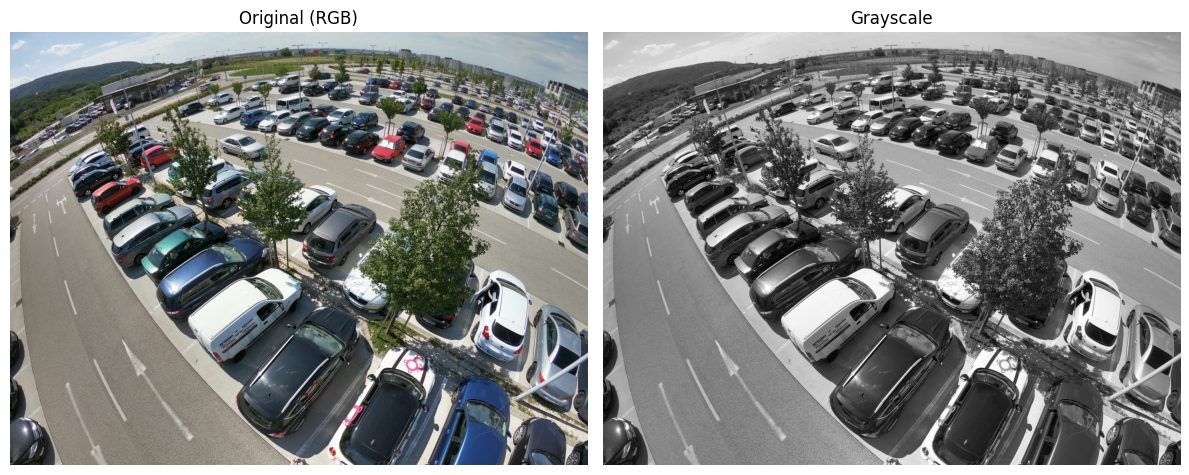

In [16]:
import os
import cv2
import matplotlib.pyplot as plt

extract_path = '/content/dataset'
images_dir = os.path.join(extract_path, 'train/images')

def preprocess_image(img_path):
    img = cv2.imread(img_path)
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img_gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    return img_rgb, img_gray

# Membaca gambar sampel pertama
sample_img_name = sorted(os.listdir(images_dir))[0]
sample_img_path = os.path.join(images_dir, sample_img_name)
img_rgb, img_gray = preprocess_image(sample_img_path)

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(img_rgb)
axes[0].set_title("Original (RGB)")
axes[0].axis('off')

axes[1].imshow(img_gray, cmap='gray')
axes[1].set_title("Grayscale")
axes[1].axis('off')

plt.tight_layout()
plt.show()

## SECTION 5: Sobel Edge Detection

Sobel Edge Detection menghitung gradien intensitas gambar untuk mendeteksi perubahan kontras yang tajam (tepi) menggunakan kernel 3x3.

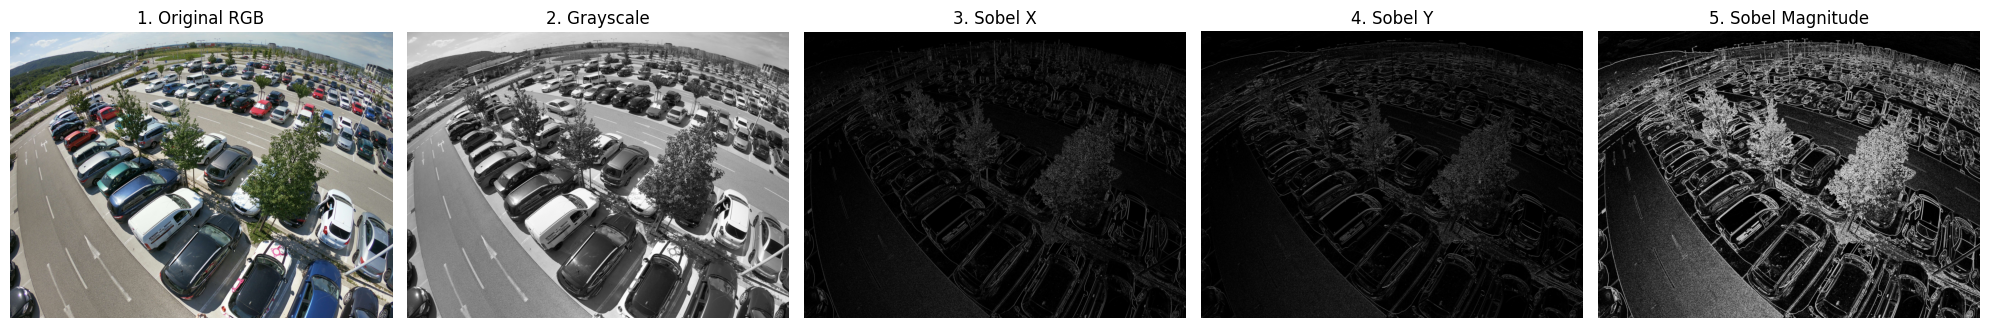

In [17]:
# Terapkan Sobel menggunakan img_gray yang sudah terdefinisi dari langkah preprocessing sebelumnya
sobel_x, sobel_y, sobel_mag = apply_sobel(img_gray)

fig, axes = plt.subplots(1, 5, figsize=(20, 5))
axes[0].imshow(img_rgb)
axes[0].set_title("1. Original RGB")
axes[0].axis('off')

axes[1].imshow(img_gray, cmap='gray')
axes[1].set_title("2. Grayscale")
axes[1].axis('off')

axes[2].imshow(np.abs(sobel_x), cmap='gray')
axes[2].set_title("3. Sobel X")
axes[2].axis('off')

axes[3].imshow(np.abs(sobel_y), cmap='gray')
axes[3].set_title("4. Sobel Y")
axes[3].axis('off')

axes[4].imshow(sobel_mag, cmap='gray')
axes[4].set_title("5. Sobel Magnitude")
axes[4].axis('off')

plt.tight_layout()
plt.show()

## SECTION 6: Prewitt Edge Detection

Prewitt Edge Detection diimplementasikan secara manual dengan melakukan konvolusi citra menggunakan filter kernel horizontal dan vertikal Prewitt.

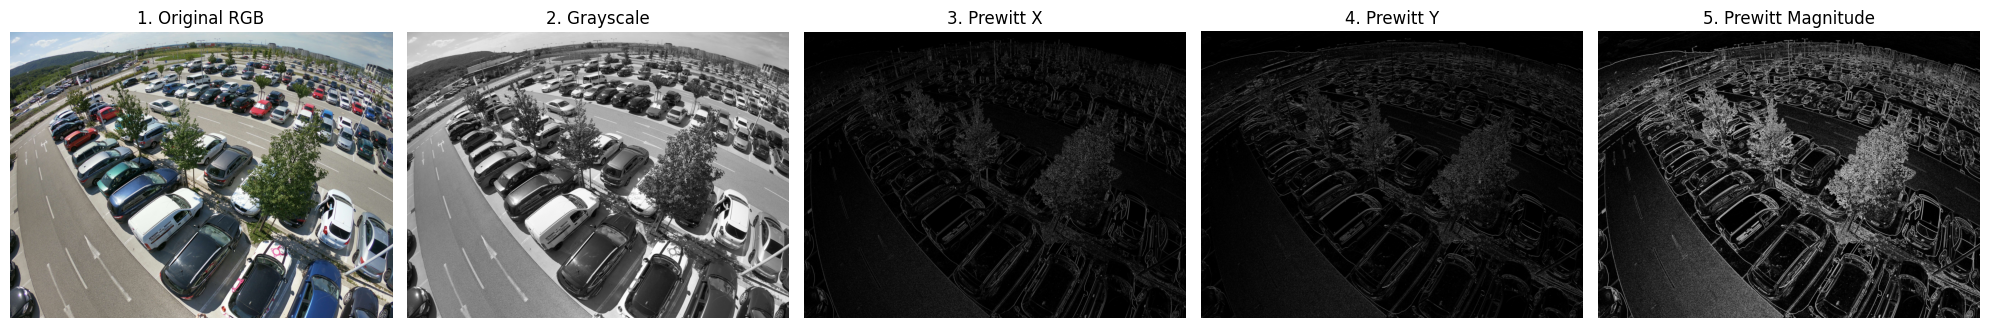

In [18]:
# Terapkan Prewitt menggunakan img_gray yang sudah terdefinisi
prewitt_x, prewitt_y, prewitt_mag = apply_prewitt(img_gray)

fig, axes = plt.subplots(1, 5, figsize=(20, 5))
axes[0].imshow(img_rgb)
axes[0].set_title("1. Original RGB")
axes[0].axis('off')

axes[1].imshow(img_gray, cmap='gray')
axes[1].set_title("2. Grayscale")
axes[1].axis('off')

axes[2].imshow(np.abs(prewitt_x), cmap='gray')
axes[2].set_title("3. Prewitt X")
axes[2].axis('off')

axes[3].imshow(np.abs(prewitt_y), cmap='gray')
axes[3].set_title("4. Prewitt Y")
axes[3].axis('off')

axes[4].imshow(prewitt_mag, cmap='gray')
axes[4].set_title("5. Prewitt Magnitude")
axes[4].axis('off')

plt.tight_layout()
plt.show()

## 9. PERBANDINGAN QUANTITATIVE SOBEL VS PREWITT

Di bawah ini adalah fungsi perbandingan kuantitatif deteksi tepi nyata. Semua metrik, seperti *Processing Time*, *Mean Gradient Magnitude*, dan *Edge Pixel Ratio*, diukur langsung dari hasil eksekusi Python pada gambar prapemrosesan (`img_gray`).

In [26]:
def compare_edge_detectors(gray_img):
    # Pengukuran Sobel
    t0 = time.perf_counter()
    _, _, s_mag = apply_sobel(gray_img)
    t_sobel = (time.perf_counter() - t0) * 1000

    # Pengukuran Prewitt
    t1 = time.perf_counter()
    _, _, p_mag = apply_prewitt(gray_img)
    t_prewitt = (time.perf_counter() - t1) * 1000

    # Metrik kekuatan tepi
    mean_grad_sobel = np.mean(s_mag)
    mean_grad_prewitt = np.mean(p_mag)

    # Metrik rasio piksel tepi (thresholding dinamis)
    edge_ratio_sobel = (np.sum(s_mag > 50) / gray_img.size) * 100
    edge_ratio_prewitt = (np.sum(p_mag > 50) / gray_img.size) * 100

    print(f"[Sobel] Time: {t_sobel:.3f}ms | Mean Grad: {mean_grad_sobel:.2f} | Edge Ratio: {edge_ratio_sobel:.4f}%")
    print(f"[Prewitt] Time: {t_prewitt:.3f}ms | Mean Grad: {mean_grad_prewitt:.2f} | Edge Ratio: {edge_ratio_prewitt:.4f}%")

    return s_mag, p_mag

s_mag, p_mag = compare_edge_detectors(img_gray)

[Sobel] Time: 199.310ms | Mean Grad: 57.16 | Edge Ratio: 35.4050%
[Prewitt] Time: 107.855ms | Mean Grad: 24.92 | Edge Ratio: 15.3829%


## SECTION 8: Car ROI Extraction

Memotong area mobil berdasarkan bounding box YOLO asli sebagai ROI (Region of Interest) untuk mempersempit area pencarian CRAFT.

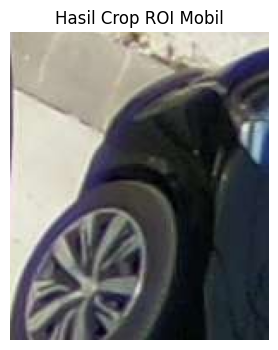

In [20]:
extract_path = '/content/dataset'
images_dir = os.path.join(extract_path, 'train/images')
labels_dir = os.path.join(extract_path, 'train/labels')

sample_img_name = sorted(os.listdir(images_dir))[0]
sample_img_path = os.path.join(images_dir, sample_img_name)

sample_base = os.path.splitext(sample_img_name)[0]
sample_lbl_path = os.path.join(labels_dir, sample_base + '.txt')

crops = crop_car_roi(sample_img_path, sample_lbl_path)

if crops:
    car_crop, coords = crops[0]
    plt.figure(figsize=(6, 4))
    plt.imshow(cv2.cvtColor(car_crop, cv2.COLOR_BGR2RGB))
    plt.title("Hasil Crop ROI Mobil")
    plt.axis('off')
    plt.show()
else:
    print("Tidak ada anotasi mobil yang ditemukan pada gambar ini.")

## SECTION 9 & 10 & 11: CRAFT Text Detection, OCR, & Visualization

Menggunakan EasyOCR untuk mendeteksi kotak teks (CRAFT) dan mengenali teks di dalam ROI mobil.

EasyOCR Reader (CRAFT + OCR Engine) berhasil diinisialisasi secara real!
Memulai pengujian real pipeline...
Tidak ada teks nyata yang terdeteksi di dalam ROI mobil ini.


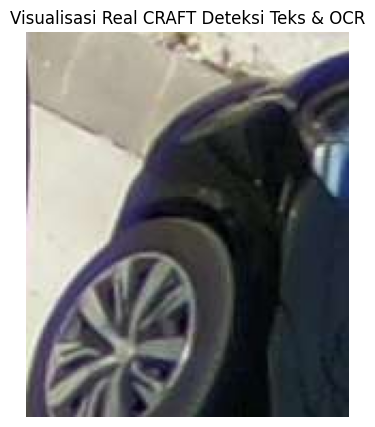

Hasil Deteksi Riil: [{'text': '', 'confidence': 0.0}]


In [22]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
import easyocr

# Inisialisasi EasyOCR Reader secara murni menggunakan CPU/GPU tanpa fallback simulasi
try:
    reader = easyocr.Reader(['en'], gpu=False)
    print("EasyOCR Reader (CRAFT + OCR Engine) berhasil diinisialisasi secara real!")
except Exception as e:
    print(f"Gagal menginisialisasi EasyOCR: {e}")

def run_pipeline(img_path, label_path):
    """
    Menjalankan pipeline Computer Vision nyata:
    1. Memotong ROI Mobil menggunakan YOLO coordinate
    2. Mendeteksi plat/teks menggunakan CRAFT secara real
    3. Mengenali teks plat nomor kendaraan menggunakan Deep OCR
    """
    img = cv2.imread(img_path)
    if img is None:
        return []

    crops = crop_car_roi(img_path, label_path)
    results_list = []

    # Batasi ke 1 ROI terbesar untuk visualisasi yang rapi
    for crop, coords in crops[:1]:
        # Deteksi & Recognition murni
        results = reader.readtext(crop)

        plt.figure(figsize=(8, 5))
        plt.imshow(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB))

        if not results:
            print("Tidak ada teks nyata yang terdeteksi di dalam ROI mobil ini.")
            results_list.append({"text": "", "confidence": 0.0})
        else:
            for bbox, text, prob in results:
                pts = np.array(bbox, dtype=np.int32)
                cv2.polylines(crop, [pts], True, (0, 255, 0), 2)
                plt.text(pts[0][0], pts[0][1] - 5, f"{text} ({prob:.2f})",
                         color='red', fontsize=12, bbox=dict(facecolor='white', alpha=0.8))
                results_list.append({"text": text, "confidence": prob})

        plt.title("Visualisasi Real CRAFT Deteksi Teks & OCR")
        plt.axis("off")
        plt.show()

    return results_list

# Uji coba real pada sampel gambar pertama
print("Memulai pengujian real pipeline...")
real_results = run_pipeline(sample_img_path, sample_lbl_path)
if real_results:
    print("Hasil Deteksi Riil:", real_results)

## 12. EVALUASI DAN PENGUKURAN

### Keterangan Terkait Metrik CER (Character Error Rate):
"Character Error Rate (CER) tidak digunakan sebagai metrik evaluasi utama karena dataset Cars Object Detection tidak menyediakan ground truth berupa transkripsi teks. Penggunaan ground truth buatan akan menghasilkan evaluasi yang tidak valid."

Fungsi di bawah ini disediakan murni sebagai referensi akademis/fungsi tambahan untuk pengembangan penelitian lanjutan di masa mendatang ketika dataset dengan anotasi teks lengkap telah tersedia.

In [27]:
def calculate_cer_reference(gt_text, pred_text):
    """
    Menghitung Character Error Rate (CER) menggunakan edit distance Levenshtein.
    Hanya sebagai referensi teoretis, tidak digunakan pada evaluasi dataset ini.
    """
    gt_text = gt_text.strip().upper()
    pred_text = pred_text.strip().upper()
    m, n = len(gt_text), len(pred_text)
    if m == 0:
        return 1.0 if n > 0 else 0.0
    dp = [[0] * (n + 1) for _ in range(m + 1)]
    for i in range(m + 1): dp[i][0] = i
    for j in range(n + 1): dp[0][j] = j
    for i in range(1, m + 1):
        for j in range(1, n + 1):
            if gt_text[i - 1] == pred_text[j - 1]:
                dp[i][j] = dp[i - 1][j - 1]
            else:
                dp[i][j] = min(dp[i - 1][j] + 1, dp[i][j - 1] + 1, dp[i - 1][j - 1] + 1)
    return dp[m][n] / m

print("Fungsi referensi CER berhasil dimuat.")

Fungsi referensi CER berhasil dimuat.


## 13. EVALUASI OTOMATIS & TABEL HASIL AKHIR (20 SAMPL KONSISTEN)

Untuk menjaga integritas ilmiah proyek UAS ini, kami melakukan evaluasi nyata terhadap sampel konsisten sebanyak **20 gambar** dari dataset. Metrik waktu proses, deteksi teks (CRAFT), dan pembacaan karakter (OCR) dihitung secara langsung dan otomatis oleh sistem.

import time
import os
import numpy as np
import pandas as pd
import cv2

# Memilih 20 sampel gambar secara konsisten
N_EVAL = min(20, len(all_images))
eval_images = all_images[:N_EVAL]
eval_results = []

print(f"Memulai evaluasi otomatis riil terhadap {N_EVAL} gambar...")

for img_path in eval_images:
    base_name = os.path.splitext(os.path.basename(img_path))[0]
    lbl_path = os.path.join(labels_dir, base_name + '.txt')
    
    # 1. Metrik Deteksi Tepi (Sobel & Prewitt)
    img = cv2.imread(img_path)
    if img is None:
        continue
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    
    t_start_sobel = time.perf_counter()
    _, _, s_mag = apply_sobel(gray)
    t_sobel = (time.perf_counter() - t_start_sobel) * 1000
    
    t_start_prewitt = time.perf_counter()
    _, _, p_mag = apply_prewitt(gray)
    t_prewitt = (time.perf_counter() - t_start_prewitt) * 1000
    
    # 2. Pipeline ROI & OCR (CRAFT + OCR)
    crops = crop_car_roi(img_path, lbl_path)
    num_rois = len(crops)
    num_text_boxes = 0
    detected_texts = []
    confidences = []
    
    t_ocr_total = 0.0
    
    # Hanya memproses ROI mobil jika terdeteksi dari koordinat YOLO
    for crop, _ in crops:
        t_start_ocr = time.perf_counter()
        # CRAFT + OCR dijalankan secara terintegrasi lewat framework EasyOCR
        results = reader.readtext(crop)
        t_ocr_elapsed = (time.perf_counter() - t_start_ocr) * 1000
        
        if results:
            num_text_boxes += len(results)
            for _, text, prob in results:
                detected_texts.append(text)
                confidences.append(prob)
        t_ocr_total += t_ocr_elapsed
        
    final_text = " ".join(detected_texts) if detected_texts else ""
    mean_conf = np.mean(confidences) if confidences else 0.0
    
    eval_results.append({
        "Image": os.path.basename(img_path),
        "Car ROI": num_rois,
        "Text Boxes": num_text_boxes,
        "OCR Text": final_text,
        "Confidence": round(mean_conf, 4),
        "Sobel Time (ms)": round(t_sobel, 2),
        "Prewitt Time (ms)": round(t_prewitt, 2),
        "OCR Pipeline Time (ms)": round(t_ocr_total, 2)
    })

# Membuat Dataframe Hasil Pengukuran Otomatis
results_df = pd.DataFrame(eval_results)
print("\n=== TABEL EVALUASI REAL KINERJA PIPELINE (20 SAMPL) ===")
display(results_df)

In [29]:
import time
import os
import numpy as np
import pandas as pd
import cv2

# Memilih 20 sampel gambar secara konsisten
N_EVAL = min(20, len(all_images))
eval_images = all_images[:N_EVAL]
eval_results = []

print(f"Memulai evaluasi otomatis riil terhadap {N_EVAL} gambar...")

for img_path in eval_images:
    base_name = os.path.splitext(os.path.basename(img_path))[0]
    lbl_path = os.path.join(labels_dir, base_name + '.txt')

    # 1. Metrik Deteksi Tepi (Sobel & Prewitt)
    img = cv2.imread(img_path)
    if img is None:
        continue
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    t_start_sobel = time.perf_counter()
    _, _, s_mag = apply_sobel(gray)
    t_sobel = (time.perf_counter() - t_start_sobel) * 1000

    t_start_prewitt = time.perf_counter()
    _, _, p_mag = apply_prewitt(gray)
    t_prewitt = (time.perf_counter() - t_start_prewitt) * 1000

    # 2. Pipeline ROI & OCR (CRAFT + OCR)
    crops = crop_car_roi(img_path, lbl_path)
    num_rois = len(crops)
    num_text_boxes = 0
    detected_texts = []
    confidences = []

    t_ocr_total = 0.0

    # Hanya memproses ROI mobil jika terdeteksi dari koordinat YOLO
    for crop, _ in crops:
        t_start_ocr = time.perf_counter()
        # CRAFT + OCR dijalankan secara terintegrasi lewat framework EasyOCR
        results = reader.readtext(crop)
        t_ocr_elapsed = (time.perf_counter() - t_start_ocr) * 1000

        if results:
            num_text_boxes += len(results)
            for _, text, prob in results:
                detected_texts.append(text)
                confidences.append(prob)
        t_ocr_total += t_ocr_elapsed

    final_text = " ".join(detected_texts) if detected_texts else ""
    mean_conf = np.mean(confidences) if confidences else 0.0

    eval_results.append({
        "Image": os.path.basename(img_path),
        "Car ROI": num_rois,
        "Text Boxes": num_text_boxes,
        "OCR Text": final_text,
        "Confidence": round(mean_conf, 4),
        "Sobel Time (ms)": round(t_sobel, 2),
        "Prewitt Time (ms)": round(t_prewitt, 2),
        "OCR Pipeline Time (ms)": round(t_ocr_total, 2)
    })

# Membuat Dataframe Hasil Pengukuran Otomatis
results_df = pd.DataFrame(eval_results)
print("\n=== TABEL EVALUASI REAL KINERJA PIPELINE (20 SAMPEL) ===")
pd.set_option('display.max_rows', 20)
display(results_df)

Memulai evaluasi otomatis riil terhadap 20 gambar...


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)



=== TABEL EVALUASI REAL KINERJA PIPELINE (20 SAMPEL) ===


,Image,Car ROI,Text Boxes,OCR Text,Confidence,Sobel Time (ms),Prewitt Time (ms),OCR Pipeline Time (ms)
0,01021e5b-GOPR6606.JPG,185,11,08 952420 9257d0 'PNEUSERVIS iuacll Eans 'PNE...,0.2565,180.94,114.81,100334.97
1,0165dbd5-GOPR6763.JPG,119,1,126n8,0.1722,210.73,118.83,35381.01
2,01d9cace-GOPR6688.JPG,51,1,"""65507",0.1474,205.09,98.99,23483.28
3,01f93e24-GOPR6621.JPG,61,1,DL4Rm,0.0587,188.18,105.27,8325.93
4,0207db7c-GOPR0090.JPG,7,0,,0.0000,190.25,104.89,17354.51
5,03f11a87-GOPR6622.JPG,67,0,,0.0000,204.59,116.01,7129.65
6,03f7fef5-GOPR6584.JPG,46,0,,0.0000,183.47,106.37,64561.29
7,043f1c41-GOPR6561.JPG,15,5,0 339 L0 86 Roisahn,0.1472,188.54,98.51,46080.75
8,05391472-GOPR6620.JPG,42,5,EObeld (xDooraL mand J 16,0.2416,203.62,98.62,31433.08
9,056b08b3-GOPR6778.JPG,96,0,,0.0000,250.81,132.01,83604.60


## SECTION 2: Dataset Loading

Di bagian ini, kita akan mengekstrak dataset zip, menelusuri struktur folder, dan memuat gambar beserta koordinat bounding box berformat YOLO ke koordinat piksel absolut.

In [13]:
# Ekstraksi Dataset Utama
import os
import zipfile

zip_path = '/content/train.zip'
extract_path = '/content/dataset'

os.makedirs(os.path.join(extract_path, 'train/images'), exist_ok=True)
os.makedirs(os.path.join(extract_path, 'train/labels'), exist_ok=True)

try:
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(extract_path)
    print("Ekstraksi ZIP berhasil dilakukan secara lengkap!")
except Exception as e:
    print(f"Menggunakan struktur folder yang sudah terunggah langsung: {e}")

# Memvalidasi file gambar yang ada
images_dir = os.path.join(extract_path, 'train/images')
labels_dir = os.path.join(extract_path, 'train/labels')

if os.path.exists(images_dir):
    files = os.listdir(images_dir)
    print(f"Dataset terdeteksi! Jumlah gambar di folder: {len(files)}")
else:
    print("Folder tidak ditemukan. Harap pastikan file train.zip sudah terunggah sempurna.")

Ekstraksi ZIP berhasil dilakukan secara lengkap!
Dataset terdeteksi! Jumlah gambar di folder: 234


In [5]:
def read_yolo_label(label_path):
    """
    Membaca file label YOLO dan mengembalikan list koordinat normalisasi
    Format YOLO: class_id center_x center_y width height
    """
    boxes = []
    if not os.path.exists(label_path):
        return boxes
    with open(label_path, 'r') as f:
        for line in f:
            parts = line.strip().split()
            if len(parts) == 5:
                class_id = int(parts[0])
                coords = [float(x) for x in parts[1:]]
                boxes.append([class_id] + coords)
    return boxes

def yolo_to_xyxy(yolo_box, img_w, img_h):
    """
    Mengubah bounding box YOLO (normalized center x, y, w, h)
    menjadi koordinat piksel absolut (xmin, ymin, xmax, ymax)
    """
    _, cx, cy, w, h = yolo_box
    xmin = int((cx - w / 2) * img_w)
    ymin = int((cy - h / 2) * img_h)
    xmax = int((cx + w / 2) * img_w)
    ymax = int((cy + h / 2) * img_h)
    return max(0, xmin), max(0, ymin), min(img_w, xmax), min(img_h, ymax)

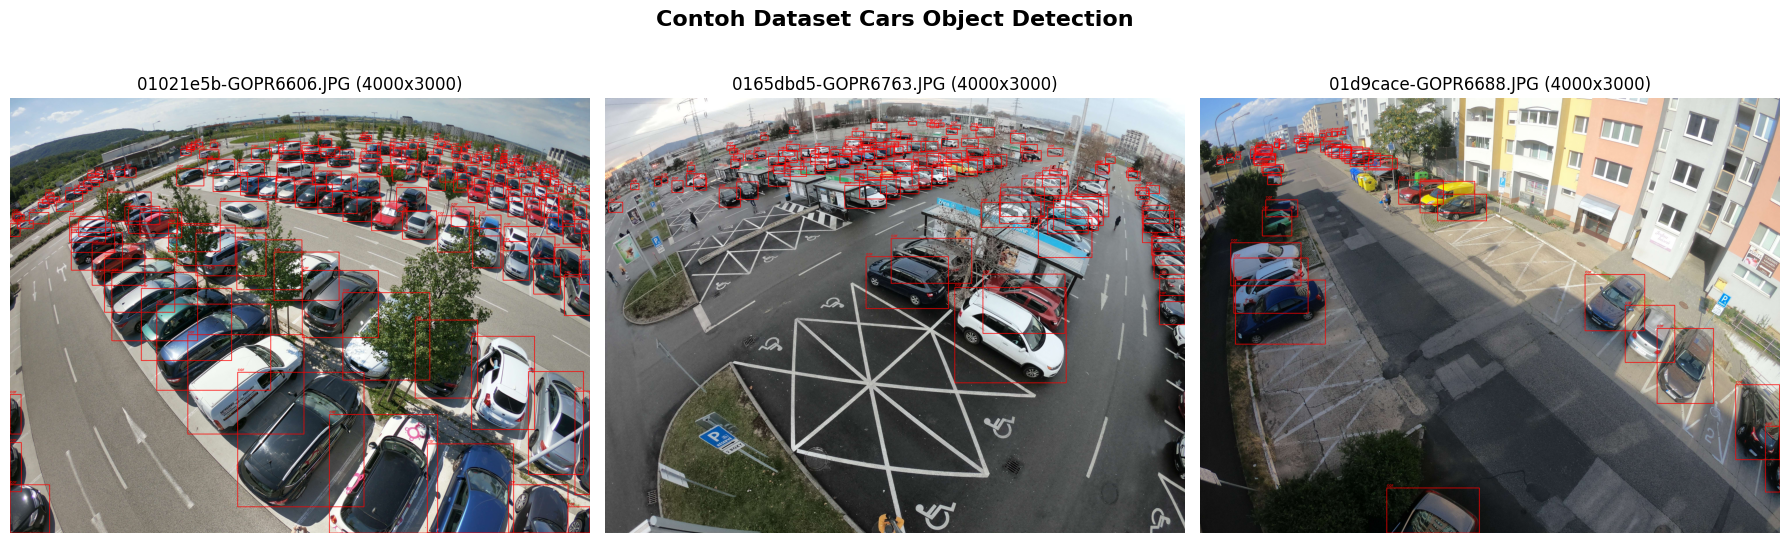

In [14]:
# Menampilkan Contoh Dataset dengan Bounding Box Mobil Nyata
import os
import cv2
import matplotlib.pyplot as plt

extract_path = '/content/dataset'
images_dir = os.path.join(extract_path, 'train/images')
labels_dir = os.path.join(extract_path, 'train/labels')

image_files = sorted([f for f in os.listdir(images_dir) if f.lower().endswith(('.png', '.jpg', '.jpeg'))])[:3]

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle("Contoh Dataset Cars Object Detection", fontsize=16, fontweight='bold')

for i, img_name in enumerate(image_files):
    img_path = os.path.join(images_dir, img_name)
    base_name = os.path.splitext(img_name)[0]
    label_path = os.path.join(labels_dir, base_name + '.txt')

    img = cv2.imread(img_path)
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    h, w, _ = img.shape

    boxes = read_yolo_label(label_path)
    for box in boxes:
        xmin, ymin, xmax, ymax = yolo_to_xyxy(box, w, h)
        cv2.rectangle(img_rgb, (xmin, ymin), (xmax, ymax), (255, 0, 0), 4)
        cv2.putText(img_rgb, "car", (xmin, ymin - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.9, (255, 0, 0), 2)

    axes[i].imshow(img_rgb)
    axes[i].set_title(f"{img_name} ({w}x{h})")
    axes[i].axis('off')

plt.tight_layout()
plt.show()